In [3]:
import numpy as np
import matplotlib.pyplot as plt

omega_p = 1.0

def leapfrog(x, v, h):

    a = -omega_p**2 * x
    v_new = v + h * a
    x_new = x + h * v_new

    return x_new, v_new


## Task 1 — Write the leapfrog function
Objective
The objective is to create a Python function called leapfrog(x, v, h) that performs one leapfrog step and returns the updated position and velocity.
In our function:
- x represents the current position.
- v represents the velocity at the previous half time level.
- h represents the time step.
- a calculates the acceleration.
- v_new stores the updated velocity after the kick.
- x_new stores the updated position after the drift.
- return x_new, v_new sends both results back to the calling program.
Here we have simply defined the leapfrog function using the given data and variables , this function that we defined will be used in further tasks when required.

In [12]:
x0 = 0.5
v0 = 0.0           ##initial conditions
h = 0.1
t_final = 20.0

n = int(t_final / h)


a0 = -omega_p**2 * x0

v_half = v0 - (h / 2) * a0

print("Initial position =", x0)
print("Initial velocity at t = 0 =", v0)
print("Initial half-step velocity =", v_half)

Initial position = 0.5
Initial velocity at t = 0 = 0.0
Initial half-step velocity = 0.025


The objective is to calculate the initial velocity at the half time level before starting the leapfrog integration.
The initial velocity is given at \(t=0\), but the leapfrog method requires the starting velocity at \(t=-h/2\).

Using the initial acceleration, the starting velocity is calculated as
$$[
v_{-1/2}=v_0-\frac{h}{2}a(x_0)
]
$$

Since
$$[
a(x_0)=-\omega_p^2x_0
]
$$
we obtain
$$[
v_{-1/2}=v_0+\frac{h}{2}\omega_p^2x_0
]$$


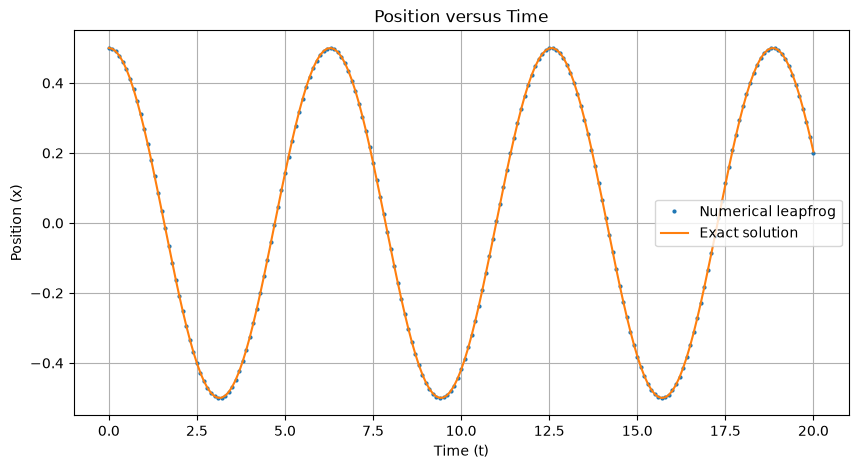

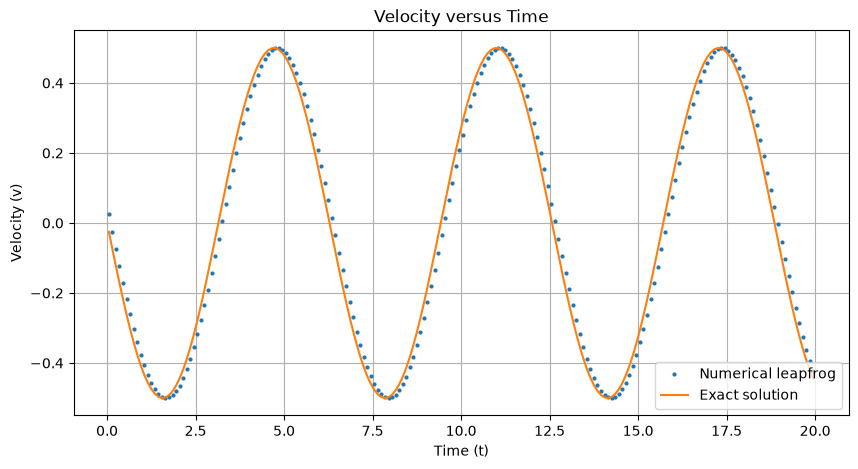

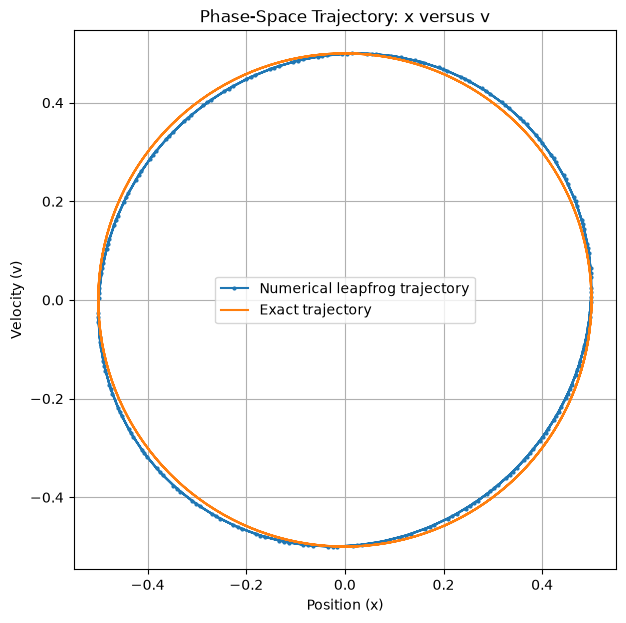

In [8]:
t_x = np.linspace(0, t_final, n + 1)
t_v = np.arange(n) * h + h / 2


x_num = np.zeros(n + 1)
v_num = np.zeros(n)

x_num[0] = x0
v_current = v_half

for i in range(n):

    v_num[i] = v_current

    x_new, v_new = leapfrog(x_num[i], v_current, h)

    x_num[i + 1] = x_new

    v_current = v_new



x_exact = 0.5 * np.cos(t_x)
v_exact = -0.5 * np.sin(t_v)



plt.figure(figsize=(10, 5))

plt.plot(t_x, x_num, 'o', markersize=2,
         label='Numerical leapfrog')
plt.plot(t_x, x_exact, '-', label='Exact solution')

plt.xlabel('Time (t)')
plt.ylabel('Position (x)')
plt.title('Position versus Time')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(10, 5))
plt.plot(t_v, v_num, 'o', markersize=2,
         label='Numerical leapfrog')
plt.plot(t_v, v_exact, '-', label='Exact solution')
plt.xlabel('Time (t)')
plt.ylabel('Velocity (v)')
plt.title('Velocity versus Time')
plt.legend()
plt.grid(True)
plt.show()



t_fine = np.linspace(0, t_final, 1000)

x_fine = 0.5 * np.cos(t_fine)
v_fine = -0.5 * np.sin(t_fine)

plt.figure(figsize=(7, 7))


plt.plot(x_num[:-1], v_num, 'o-', markersize=2,
         label='Numerical leapfrog trajectory')


plt.plot(x_fine, v_fine, '-', label='Exact trajectory')

plt.xlabel('Position (x)')
plt.ylabel('Velocity (v)')
plt.title('Phase-Space Trajectory: x versus v')
plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()

The objective is to integrate the equations from (t=0) to (t=20), using a time step (h=0.1), and compare the numerical solution with the exact solution.

The number of time steps is calculated as

$$
N=\frac{t_f-t_0}{h}
=\frac{20-0}{0.1}=200
$$

Our code creates arrays to store the numerical position and velocity. The initial position is assigned to the first element of the position array, and the initialized half-step velocity is used to start the integration.

A for loop repeatedly calls the leapfrog() function. At each iteration, the updated position is stored in x_num, and the velocity is carried forward for the next iteration.

The exact solutions are evaluated using

$$
x_{\mathrm{exact}}(t)=0.5\cos(\omega_pt)
$$

$$
v_{\mathrm{exact}}(t)=-0.5\sin(\omega_pt)
$$

The code then generates three separate graphs.

In [ ]:
t = [0, 20]
h_values = [0.2, 0.1, 0.05, 0.025]

x_stag = {}
time_stag = {}
x_exact_stag = {}
err_stag = {}

for h in h_values:

    n = int((t[1] - t[0]) / h)
    timestep = np.linspace(t[0], t[1], n + 1)

   
    x_exact = 0.5 * np.cos(omega_p * timestep)

 
    x_num = np.zeros(n + 1)
    v_half = np.zeros(n)

    x_num[0] = 0.5
    v0 = 0.0

   
    a0 = -omega_p**2 * x_num[0]
    v_current = v0 - (h / 2) * a0

   
    for j in range(n):

        v_half[j] = v_current

        x_num[j + 1], v_current = leapfrog(
            x_num[j], v_current, h
        )

    x_stag[h] = x_num
    time_stag[h] = timestep
    x_exact_stag[h] = x_exact

    
    err_stag[h] = np.abs(x_num - x_exact)




fig, axs = plt.subplots(2, 2, figsize=(12, 8),
                        sharex=True, sharey=True)

for i, h in enumerate(h_values):

    ax = axs.flat[i]

    ax.plot(time_stag[h], x_exact_stag[h],
            'k--', linewidth=1.2, label="Exact")

    ax.plot(time_stag[h], x_stag[h],
            label="Leapfrog")

    ax.set_title(f"h = {h}")
    ax.set_xlabel("Time (t)")
    ax.set_ylabel("Position (x)")
    ax.legend()
    ax.grid(True)

fig.suptitle("Leapfrog vs Exact Solution (Staggered Start)")
plt.tight_layout()
plt.show()



fig, axs = plt.subplots(2, 2, figsize=(12, 8),
                        sharex=True, sharey=True)

for i, h in enumerate(h_values):

    ax = axs.flat[i]

    ax.plot(time_stag[h], err_stag[h],
            label="Absolute error")

    ax.set_title(f"h = {h}")
    ax.set_xlabel("Time (t)")
    ax.set_ylabel("Absolute error in x")
    ax.legend()
    ax.grid(True)

fig.suptitle("Position Error for Different h (Staggered Start)")
plt.tight_layout()
plt.show()

x_unstag = {}
time_unstag = {}
x_exact_unstag = {}
err_unstag = {}

for h in h_values:

    n = int((t[1] - t[0]) / h)
    timestep = np.linspace(t[0], t[1], n + 1)

    x_exact = 0.5 * np.cos(omega_p * timestep)

    x_num = np.zeros(n + 1)
    v_half = np.zeros(n)

    x_num[0] = 0.5
    v0 = 0.0

    v_current = v0

    for j in range(n):

        v_half[j] = v_current

        x_num[j + 1], v_current = leapfrog(
            x_num[j], v_current, h
        )

    x_unstag[h] = x_num
    time_unstag[h] = timestep
    x_exact_unstag[h] = x_exact

    err_unstag[h] = np.abs(x_num - x_exact)



fig, axs = plt.subplots(2, 2, figsize=(12, 8),
                        sharex=True, sharey=True)

for i, h in enumerate(h_values):

    ax = axs.flat[i]

    ax.plot(time_unstag[h], x_exact_unstag[h],
            'k--', linewidth=1.2, label="Exact")

    ax.plot(time_unstag[h], x_unstag[h],
            label="Leapfrog")

    ax.set_title(f"h = {h}")
    ax.set_xlabel("Time (t)")
    ax.set_ylabel("Position (x)")
    ax.legend()
    ax.grid(True)

fig.suptitle("Leapfrog vs Exact Solution (Unstaggered Start)")
plt.tight_layout()
plt.show()

fig, axs = plt.subplots(2, 2, figsize=(12, 8),
                        sharex=True, sharey=True)

for i, h in enumerate(h_values):

    ax = axs.flat[i]

    ax.plot(time_unstag[h], err_unstag[h],
            label="Absolute error")

    ax.set_title(f"h = {h}")
    ax.set_xlabel("Time (t)")
    ax.set_ylabel("Absolute error in x")
    ax.legend()
    ax.grid(True)

fig.suptitle("Position Error for Different h (Unstaggered Start)")
plt.tight_layout()
plt.show()

e_stag = []
e_unstag = []

for h in h_values:

    e_stag.append(np.max(err_stag[h]))
    e_unstag.append(np.max(err_unstag[h]))

e_stag = np.array(e_stag)
e_unstag = np.array(e_unstag)

plt.figure(figsize=(8, 5))

plt.plot(h_values, e_stag, '-o', label="Staggered")
plt.plot(h_values, e_unstag, '-o', label="Unstaggered")

plt.xlabel("Time step h")
plt.ylabel("Maximum absolute error in x")
plt.title("Maximum Error for Different Time Steps")
plt.gca().invert_xaxis()
plt.legend()
plt.grid(True)
plt.show()

p_stag = np.log2(e_stag[:-1] / e_stag[1:])
p_unstag = np.log2(e_unstag[:-1] / e_unstag[1:])

print("Staggered maximum errors:  ", e_stag)
print("Unstaggered maximum errors:", e_unstag)

print("\nStaggered observed order:")
print(p_stag)

print("\nUnstaggered observed order:")
print(p_unstag)

plt.figure(figsize=(8, 5))

plt.loglog(h_values, e_stag, '-o', label="Staggered")
plt.loglog(h_values, e_unstag, '-o', label="Unstaggered")

plt.xlabel("Time step h")
plt.ylabel("Maximum absolute error in x")
plt.title("Convergence of Leapfrog Method")
plt.legend()
plt.grid(True, which="both")
plt.show()


The objective is to study how the numerical error changes when the time step is reduced. The analysis compares the correctly staggered initialization with the unstaggered initialization.

The four time steps used in our code are

$$
h=0.2,\quad 0.1,\quad 0.05,\quad 0.025
$$

The integration is performed from (t=0) to (t=20) for every time step.

The exact position is

$$
x_{\mathrm{exact}}(t)=0.5\cos(\omega_pt)
$$

The absolute position error at each time level is calculated as

$$
e_n=|x_n-x_{\mathrm{exact}}(t_n)|
$$

The maximum absolute error over the complete simulation is

$$
\boxed{E(h)=\max_n|x_n-x_{\mathrm{exact}}(t_n)|}
$$

The observed convergence order is calculated by comparing the maximum errors for two consecutive time steps:

$$
\boxed{p=\log_2\left(\frac{e(h)}{e(h/2)}\right)}
$$

If halving the time step reduces the error by a factor of four, then (p=2). If it reduces the error by a factor of two, then (p=1).

Part A — Staggered Initialization

For the staggered case, the starting velocity is calculated using

$$
v_{-1/2}=v_0-\frac h2a(x_0)
$$

Our code loops over all four time steps. For each (h), it creates arrays for position and velocity, calculates the starting half-step velocity, and performs the leapfrog integration.

The resulting position, time, exact solution, and absolute error are stored in dictionaries using the time step (h) as the key. This allows the data for each time step to be retrieved separately for plotting.

Graph 1: Position Versus Time for the Staggered Start

The code uses a (2\times2) grid of subplots, with one subplot for each time step. Each subplot contains the exact solution as a dashed black curve and the numerical leapfrog solution as a separate curve.

This arrangement allows us to compare the numerical solution with the exact solution for all four time steps.

Graph 2: Absolute Position Error Versus Time for the Staggered Start

A second (2\times2) grid plots the absolute position error against time for each (h).

These plots show how the error develops during the simulation. Smaller time steps are expected to produce smaller errors overall.

Part B — Unstaggered Initialization

For the unstaggered case, the initial half-step velocity is set directly to the initial velocity:

$$
v_{-1/2}=v_0=0
$$

Unlike the staggered case, no half-step correction is applied.

Our code repeats the integration for all four time steps and stores the numerical positions, exact positions, time arrays, and absolute errors separately from the staggered results.

Graph 3: Position Versus Time for the Unstaggered Start

A (2\times2) grid compares the numerical and exact position curves for each time step. This allows us to see how the unstaggered initialization affects the numerical solution.

Graph 4: Absolute Position Error Versus Time for the Unstaggered Start

A second (2\times2) grid displays the absolute error for all four time steps. These plots can be compared with the staggered error plots to investigate the effect of the initial velocity choice.

Part C — Maximum Error Comparison

After completing both experiments, our code calculates the maximum absolute error for each time step using np.max().

The errors are stored in two arrays:

e_stag: maximum errors for the staggered start.

e_unstag: maximum errors for the unstaggered start.

Graph 5: Maximum Error Versus Time Step

Both sets of maximum errors are plotted on the same graph. The horizontal axis represents the time step (h), and the vertical axis represents the maximum absolute position error.

The axis is inverted so that the smaller time steps appear toward the right. This makes it easy to observe how the errors change as the time step decreases.

Part D — Observed Convergence Order

The code calculates the observed order for each consecutive pair of time steps:

$$
p_{\mathrm{stag}}=
\log_2\left(
\frac{e_{\mathrm{stag}}(h)}
{e_{\mathrm{stag}}(h/2)}
\right)
$$

$$
p_{\mathrm{un stag}}=
\log_2\left(
\frac{e_{\mathrm{un stag}}(h)}
{e_{\mathrm{un stag}}(h/2)}
\right)
$$

The resulting values are printed separately for the two initializations.

The final convergence plot displays maximum error against time step on logarithmic axes. The staggered and unstaggered results can be compared directly.

For a method whose error behaves as (E(h)\propto h^p), the slope on a log-log graph corresponds to the convergence order (p).

Result

Task 4 compares the numerical accuracy for four time steps and two initialization procedures. The position plots, error plots, maximum-error comparison, and printed observed orders provide the evidence needed to discuss convergence.

The expected behaviour is approximately second-order convergence for the correctly staggered initialization and approximately first-order convergence for the unstaggered initialization. The actual orders should be reported from the values printed by our code.



## Task 5: Order of the Leapfrog Method

The leapfrog method is given by

$$
v_{n+\frac12}=v_{n-\frac12}+h a(x_n)
$$

and

$$
x_{n+1}=x_n+h v_{n+\frac12}
$$

Similarly, the position update for the previous time step is

$$
x_n=x_{n-1}+h v_{n-\frac12}
$$

Rearranging the previous equation,

$$
v_{n-\frac12}=\frac{x_n-x_{n-1}}{h}
$$

From the current position update,

$$
v_{n+\frac12}=\frac{x_{n+1}-x_n}{h}
$$

Substituting these expressions into the velocity update equation gives

$$
\frac{x_{n+1}-x_n}{h}
=
\frac{x_n-x_{n-1}}{h}+h a(x_n)
$$

Multiplying both sides by \(h\),

$$
x_{n+1}-x_n=x_n-x_{n-1}+h^2a(x_n)
$$

Rearranging,

$$
\boxed{x_{n+1}-2x_n+x_{n-1}=h^2a(x_n)}
$$

For electron plasma oscillation,

$$
a(x_n)=-\omega_p^2x_n
$$

Therefore,

$$
\boxed{x_{n+1}-2x_n+x_{n-1}
=-\omega_p^2h^2x_n}
$$

This is the central difference formula for the second-order differential equation

$$
\frac{d^2x}{dt^2}=-\omega_p^2x
$$

The central difference approximation to the second derivative is

$$
\frac{d^2x}{dt^2}
\approx
\frac{x_{n+1}-2x_n+x_{n-1}}{h^2}
$$

Its local truncation error is \(O(h^2)\). Hence, the leapfrog method is **second-order accurate** when initialized with the correct staggered velocity.

## Task 6: Stability Limit of the Leapfrog Method

From Task 5, the difference equation is

$$
x_{n+1}-2x_n+x_{n-1}
=-\omega_p^2h^2x_n
$$

Rearranging,

$$
x_{n+1}-(2-\omega_p^2h^2)x_n+x_{n-1}=0
$$

Assume a solution of the form

$$
x_n=r^n
$$

Substituting into the difference equation,

$$
r^{n+1}-(2-\omega_p^2h^2)r^n+r^{n-1}=0
$$

Dividing by \(r^{n-1}\),

$$
r^2-(2-\omega_p^2h^2)r+1=0
$$

This is the characteristic equation of the numerical scheme.

Let

$$
\alpha=\omega_ph
$$

Then the characteristic equation becomes

$$
r^2-(2-\alpha^2)r+1=0
$$

Using the quadratic formula,

$$
r=\frac{2-\alpha^2
\pm\sqrt{(2-\alpha^2)^2-4}}{2}
$$

Simplifying,

$$
r=1-\frac{\alpha^2}{2}
\pm\frac12\sqrt{\alpha^4-4\alpha^2}
$$

For oscillatory stability, the characteristic roots must lie on the unit circle. This requires

$$
|2-\alpha^2|\leq 2
$$

Therefore,

$$
-2\leq 2-\alpha^2\leq 2
$$

Subtracting 2,

$$
-4\leq-\alpha^2\leq0
$$

Hence,

$$
0\leq\alpha^2\leq4
$$

Since \(\alpha=\omega_ph\),

$$
\boxed{\omega_ph\leq2}
$$

